# F26-11 — Phase 5: Experimental Results, Theoretical Insights and Reproducibility
**Lightweight Speech Emotion Recognition Using Hand-Crafted Acoustic Features**

AI2002 Artificial Intelligence (BS-SE-5A), FAST-NUCES Lahore, Fall 2026 · Track B (Research & Development)
Members: 22L-7786 (Lead), 23L-3002, 23L-3102 · Instructor: Hajra Waheed

Phase 4 showed *what* happens: the model is near-perfect only with leakage, much weaker for new speakers
(and worse for men), and near chance on a new dataset. This notebook tests *why*, with four small experiments,
and shows that the analysis can be reproduced:

1. **Reproducibility**: re-train the baselines from the feature cache and compare with the saved results.
2. **Speaker vs emotion**: do the features describe *who* speaks more than *how they feel*?
3. **Speaker normalisation**: if speaker identity is the problem, removing it should help new speakers.
4. **Test-set size**: how much does accuracy change from one random split to another?
5. **Time position**: does the paper's flattened input break when speech starts at a different time?

Only scikit-learn models are trained here, so the notebook runs in a few minutes on a laptop CPU.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

ROOT = Path.cwd() if (Path.cwd() / "features").exists() else Path.cwd().parent
OUT = ROOT / "phase5"
(OUT / "figures").mkdir(parents=True, exist_ok=True)

SEED = 42
EMOTIONS = ["neutral", "happy", "sad", "angry", "fearful", "disgust", "surprised"]
FOLDS = [range(1, 7), range(7, 13), range(13, 19), range(19, 25)]
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
                     "font.size": 9})

## 0. Data and helper functions (same as Phase 3)

In [2]:
def load_features(name):
    """Load the cached feature array (clips, 4 versions, 108 frames, 34 features) and the label table."""
    X = np.load(ROOT / "features" / f"{name}.npz")["X"]
    meta = pd.read_csv(ROOT / "features" / f"{name}.csv")
    return X, meta


def get_frames(X, idx, augment):
    """Frame matrices of the chosen clips: all 4 versions if augment, else the original only."""
    frames = X[idx] if augment else X[idx, :1]
    return frames.reshape(-1, 108, 34), frames.shape[1]


def to_summary(frames):
    """(n, 108, 34) -> (n, 68): mean and std of every feature over time."""
    return np.concatenate([frames.mean(axis=1), frames.std(axis=1)], axis=1)


def to_vectors(frames):
    """(n, 108, 34) -> (n, 3672) in the paper's order (all ZCR frames, then RMS, ...)."""
    return frames.transpose(0, 2, 1).reshape(len(frames), -1)


def make_svm(probability=True):
    """The SVM baseline of Phase 3: standardise, then RBF kernel with C = 10."""
    return make_pipeline(StandardScaler(), SVC(C=10, gamma="scale", probability=probability, random_state=SEED))


def random_split(y, seed=SEED):
    """Stratified 80/10/10 split of clip indices."""
    idx = np.arange(len(y))
    train, rest = train_test_split(idx, test_size=0.2, stratify=y, random_state=seed)
    val, test = train_test_split(rest, test_size=0.5, stratify=y[rest], random_state=seed)
    return train, val, test


def fit_predict(model, X, y, train, test, transform=to_summary):
    """Train on the augmented training clips and predict the original test clips."""
    train_frames, n = get_frames(X, train, augment=True)
    model.fit(transform(train_frames), np.repeat(y[train], n))
    test_x = transform(get_frames(X, test, augment=False)[0])
    if hasattr(model, "predict_proba"):
        return model.predict_proba(test_x).argmax(axis=1)
    return model.predict(test_x)


X_rav, meta_rav = load_features("ravdess")
X_tess, meta_tess = load_features("tess")
y_rav, y_tess = meta_rav["label"].values, meta_tess["label"].values
print("RAVDESS", X_rav.shape, "| TESS", X_tess.shape)

RAVDESS (1440, 4, 108, 34) | TESS (2800, 4, 108, 34)


## 1. Reproducibility: re-train the baselines and compare with the saved predictions
`scripts/run_experiments.py` saved every prediction of the full experiment run. If our pipeline is
reproducible, re-training the same model with the same seed on the same split must give the same predictions.

In [3]:
saved = pd.concat([pd.read_csv(ROOT / "results" / f"predictions_{e}.csv") for e in ["paper", "speaker"]])


def compare_with_saved(experiment, model_name, new_pred):
    """Share of clips where the new prediction equals the saved one, and both accuracies."""
    old = saved[(saved["experiment"] == experiment) & (saved["model"] == model_name)]
    return {"experiment": experiment, "model": model_name, "same predictions": (old["pred"].values == new_pred).mean(),
            "saved accuracy": (old["pred"] == old["label"]).mean(),
            "new accuracy": (new_pred == old["label"].values).mean()}


train, val, test = random_split(y_rav)
rows = []
start = time.time()
for name, model in [("SVM", make_svm()), ("RandomForest", RandomForestClassifier(300, n_jobs=-1, random_state=SEED))]:
    rows.append(compare_with_saved("paper", name, fit_predict(model, X_rav, y_rav, train, test)))

svm_speaker = np.zeros(0, dtype=int)
for actors in FOLDS:
    test_idx = np.where(meta_rav["actor"].isin(actors))[0]
    train_idx = np.where(~meta_rav["actor"].isin(actors))[0]
    train_idx, _ = train_test_split(train_idx, test_size=0.1, stratify=y_rav[train_idx], random_state=SEED)
    svm_speaker = np.concatenate([svm_speaker, fit_predict(make_svm(), X_rav, y_rav, train_idx, test_idx)])
rows.append(compare_with_saved("speaker", "SVM", svm_speaker))
reproduce = pd.DataFrame(rows)
reproduce.to_csv(OUT / "reproducibility.csv", index=False)
print(reproduce.round(4).to_string(index=False))
print(f"({time.time() - start:.0f} s)")

experiment        model  same predictions  saved accuracy  new accuracy
     paper          SVM            1.0000          0.7708        0.7708
     paper RandomForest            0.8958          0.6944        0.6736
   speaker          SVM            0.9868          0.4910        0.4931
(56 s)


In [4]:
summary = json.load(open(ROOT / "results" / "summary.json"))
preds = pd.concat([pd.read_csv(f) for f in sorted((ROOT / "results").glob("predictions_*.csv"))])
checked = 0
for r in summary["model_comparison"]:
    d = preds[(preds["experiment"] == r["experiment"]) & (preds["model"] == r["model"]) & (preds["variant"] == "full")]
    assert abs((d["pred"] == d["label"]).mean() - r["acc"]) < 1e-12
    checked += 1
print(f"{checked} of {len(summary['model_comparison'])} reported accuracies re-computed from the saved predictions: all equal.")

30 of 30 reported accuracies re-computed from the saved predictions: all equal.


## 2. Do the features describe the speaker more than the emotion?
For each of the 68 summary features we measure how much of its variation is explained by the speaker and how
much by the emotion (**eta squared** = variance between group means / total variance; 0 = nothing, 1 = all).
We also train the same SVM to recognise the *speaker* (24 classes) instead of the emotion (7 classes).

In [5]:
def eta_squared(values, groups):
    """Share of the variance of each column explained by the group means."""
    total = values.var(axis=0)
    means = pd.DataFrame(values).groupby(groups).transform("mean").values
    return means.var(axis=0) / total


summary_rav = to_summary(X_rav[:, 0])
eta_speaker = eta_squared(summary_rav, meta_rav["speaker"].values)
eta_emotion = eta_squared(summary_rav, meta_rav["emotion"].values)
groups = {"ZCR": [0], "RMS energy": [1], "MFCC": list(range(2, 22)), "Chroma": list(range(22, 34))}
eta = pd.DataFrame({name: {"speaker": np.r_[eta_speaker[cols], eta_speaker[[c + 34 for c in cols]]].mean(),
                           "emotion": np.r_[eta_emotion[cols], eta_emotion[[c + 34 for c in cols]]].mean()}
                    for name, cols in groups.items()}).T
eta.loc["all 68 features"] = [eta_speaker.mean(), eta_emotion.mean()]
print((100 * eta).round(1))
print(f"Features where the speaker explains more than the emotion: {(eta_speaker > eta_emotion).sum()} of 68")

                   speaker    emotion
ZCR              50.400002   3.800000
RMS energy        4.000000  34.200001
MFCC             31.600000   9.700000
Chroma           21.700001   2.400000
all 68 features  27.900000   7.600000
Features where the speaker explains more than the emotion: 65 of 68


In [6]:
folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
speaker_id = cross_val_score(make_svm(False), summary_rav, meta_rav["speaker"], cv=folds).mean()
emotion_id = cross_val_score(make_svm(False), summary_rav, y_rav, cv=folds).mean()
print(f"Same SVM, same 68 features, 5-fold CV on the 1,440 original clips:")
print(f"  who is speaking (24 actors, chance 4.2%): {100 * speaker_id:.1f}%")
print(f"  which emotion   (7 classes, chance 20.0%): {100 * emotion_id:.1f}%")

Same SVM, same 68 features, 5-fold CV on the 1,440 original clips:
  who is speaking (24 actors, chance 4.2%): 95.0%
  which emotion   (7 classes, chance 20.0%): 74.4%


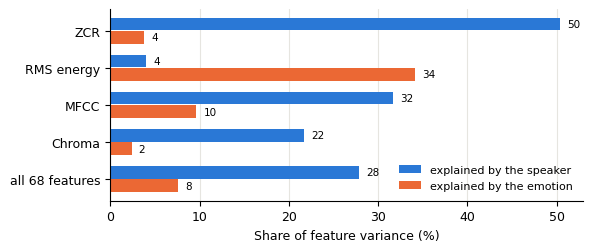

In [7]:
fig, ax = plt.subplots(figsize=(6, 2.6))
y = np.arange(len(eta))
ax.barh(y - 0.18, 100 * eta["speaker"], height=0.34, color=BLUE, label="explained by the speaker")
ax.barh(y + 0.18, 100 * eta["emotion"], height=0.34, color=ORANGE, label="explained by the emotion")
for i, (s, e) in enumerate(zip(eta["speaker"], eta["emotion"])):
    ax.text(100 * s + 0.8, i - 0.18, f"{100 * s:.0f}", va="center", fontsize=7.5)
    ax.text(100 * e + 0.8, i + 0.18, f"{100 * e:.0f}", va="center", fontsize=7.5)
ax.set_yticks(y, eta.index)
ax.invert_yaxis()
ax.set_xlabel("Share of feature variance (%)")
ax.grid(axis="x", color="#e6e5e0")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(OUT / "figures" / "fig1_speaker_vs_emotion.png", dpi=200)
plt.show()

## 3. Speaker normalisation: remove the speaker, keep the emotion
Each speaker's features are z-scored with that speaker's own mean and standard deviation (computed from the
speaker's original clips, **without labels**, so this is allowed for a new speaker too). What remains is how a
clip differs from the speaker's normal voice. We repeat the unseen-speaker protocol (4 folds) and the
RAVDESS → TESS test with the SVM, with and without this step.

In [8]:
def speaker_normalise(X, meta):
    """Z-score the 68 summary features of every version of every clip with its speaker's statistics."""
    out = np.zeros(X.shape[:2] + (68,))
    for speaker in meta["speaker"].unique():
        idx = np.where(meta["speaker"] == speaker)[0]
        own = to_summary(X[idx, 0])
        mean, std = own.mean(axis=0), own.std(axis=0) + 1e-8
        for v in range(X.shape[1]):
            out[idx, v] = (to_summary(X[idx, v]) - mean) / std
    return out


def svm_on_summaries(S_train, y_train, S_test):
    """Fit the SVM on ready-made summary features (all versions of the training clips) and predict."""
    model = make_svm()
    model.fit(S_train.reshape(-1, 68), np.repeat(y_train, S_train.shape[1]))
    return model.predict_proba(S_test[:, 0]).argmax(axis=1)


def speaker_cv(S):
    """Unseen-speaker 4-fold protocol on summary features S (clips, versions, 68); returns predictions."""
    pred = np.zeros(len(y_rav), dtype=int)
    for actors in FOLDS:
        test_idx = np.where(meta_rav["actor"].isin(actors))[0]
        train_idx = np.where(~meta_rav["actor"].isin(actors))[0]
        train_idx, _ = train_test_split(train_idx, test_size=0.1, stratify=y_rav[train_idx], random_state=SEED)
        pred[test_idx] = svm_on_summaries(S[train_idx], y_rav[train_idx], S[test_idx])
    return pred


def by_gender(pred):
    """Overall, male and female accuracy for RAVDESS predictions."""
    ok = pred == y_rav
    return ok.mean(), ok[meta_rav["gender"] == "male"].mean(), ok[meta_rav["gender"] == "female"].mean()


start = time.time()
S_plain = np.stack([to_summary(X_rav[:, v]) for v in range(4)], axis=1)
S_norm = speaker_normalise(X_rav, meta_rav)
T_plain = np.stack([to_summary(X_tess[:, v]) for v in range(4)], axis=1)
T_norm = speaker_normalise(X_tess, meta_tess)

rows = []
for name, S, T in [("without", S_plain, T_plain), ("with speaker normalisation", S_norm, T_norm)]:
    overall, male, female = by_gender(speaker_cv(S))
    train_idx, _ = train_test_split(np.arange(len(y_rav)), test_size=0.1, stratify=y_rav, random_state=SEED)
    tess = (svm_on_summaries(S[train_idx], y_rav[train_idx], T) == y_tess).mean()
    rows.append({"SVM": name, "unseen speakers": overall, "male": male, "female": female,
                 "gap (F - M)": female - male, "RAVDESS -> TESS": tess})
normalisation = pd.DataFrame(rows).set_index("SVM")
normalisation.to_csv(OUT / "speaker_normalisation.csv")
print((100 * normalisation).round(1))
print(f"({time.time() - start:.0f} s)")

                            unseen speakers  male  female  gap (F - M)  \
SVM                                                                      
without                                49.3  45.6    53.1          7.5   
with speaker normalisation             59.2  53.8    64.7         11.0   

                            RAVDESS -> TESS  
SVM                                          
without                                24.2  
with speaker normalisation             34.8  
(98 s)


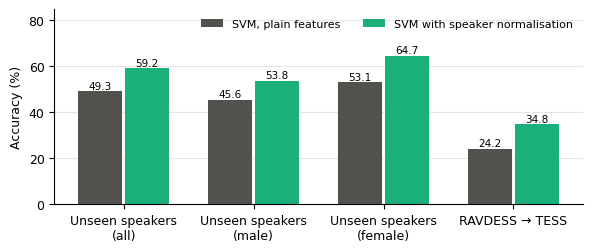

In [9]:
fig, ax = plt.subplots(figsize=(6, 2.6))
cols = ["unseen speakers", "male", "female", "RAVDESS -> TESS"]
x = np.arange(len(cols))
for k, (name, color) in enumerate([("without", GRAY), ("with speaker normalisation", AQUA)]):
    values = 100 * normalisation.loc[name, cols]
    ax.bar(x + (k - 0.5) * 0.36, values, width=0.34, color=color, label=f"SVM {name}" if k else "SVM, plain features")
    for xi, v in zip(x, values):
        ax.text(xi + (k - 0.5) * 0.36, v + 1, f"{v:.1f}", ha="center", fontsize=7.5)
ax.set_xticks(x, ["Unseen speakers\n(all)", "Unseen speakers\n(male)", "Unseen speakers\n(female)",
                  "RAVDESS → TESS"])
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 85)
ax.grid(axis="y", color="#e6e5e0")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
plt.tight_layout()
plt.savefig(OUT / "figures" / "fig2_speaker_normalisation.png", dpi=200)
plt.show()

## 4. How much does accuracy depend on the random split?
The paper protocol tests on only 144 clips. We repeat it with 10 different random splits (seeds 0–9) using the
SVM, which trains in seconds. Theory: with n = 144 and accuracy p ≈ 0.77, the standard error of one
measurement is sqrt(p(1 − p) / n) ≈ 3.5 points.

In [10]:
start = time.time()
split_acc = []
for seed in range(10):
    tr, _, te = random_split(y_rav, seed)
    split_acc.append((fit_predict(make_svm(False), X_rav, y_rav, tr, te) == y_rav[te]).mean())
split_acc = np.array(split_acc)
p = split_acc.mean()
print("SVM accuracy on 10 random splits (%):", np.round(100 * split_acc, 1))
print(f"mean {100 * p:.1f}, std {100 * split_acc.std(ddof=1):.1f}, range {100 * split_acc.min():.1f}–"
      f"{100 * split_acc.max():.1f}; theoretical standard error {100 * np.sqrt(p * (1 - p) / 144):.1f}")
print(f"({time.time() - start:.0f} s)")

SVM accuracy on 10 random splits (%): [72.9 74.3 72.9 79.9 77.1 72.9 83.3 81.9 79.9 73.6]
mean 76.9, std 4.1, range 72.9–83.3; theoretical standard error 3.5
(21 s)


## 5. Does the flattened input depend on *when* the speech happens?
The paper's models read a 3,672-value vector in which every value belongs to a fixed time frame. If the speech
starts later, the same values move to other positions. The 68-value summary (mean and std over time) ignores
position. We train an SVM on each input (random split) and test it on the test clips shifted later in time
by 0–40 frames (one frame = 23 ms), filling the start with zeros like the padding in short clips.

In [11]:
def shift(frames, k):
    """Delay every clip by k frames: zeros at the start, the end is cut off."""
    out = np.zeros_like(frames)
    out[:, k:] = frames[:, :108 - k]
    return out


start = time.time()
train_frames, n = get_frames(X_rav, train, augment=True)
test_frames, _ = get_frames(X_rav, test, augment=False)
shifts = [0, 5, 10, 20, 40]
position = {}
for name, transform in [("flattened 3,672 values (paper input)", to_vectors), ("68-value summary", to_summary)]:
    model = make_svm(False).fit(transform(train_frames), np.repeat(y_rav[train], n))
    position[name] = [(model.predict(transform(shift(test_frames, k))) == y_rav[test]).mean() for k in shifts]
position = pd.DataFrame(position, index=pd.Index(shifts, name="shift (frames)"))
position.to_csv(OUT / "time_shift.csv")
print((100 * position).round(1))
print(f"({time.time() - start:.0f} s)")

                flattened 3,672 values (paper input)  68-value summary
shift (frames)                                                        
0                                               67.4              77.8
5                                               52.1              75.7
10                                              41.0              68.8
20                                              29.2              53.5
40                                              23.6              29.9
(127 s)


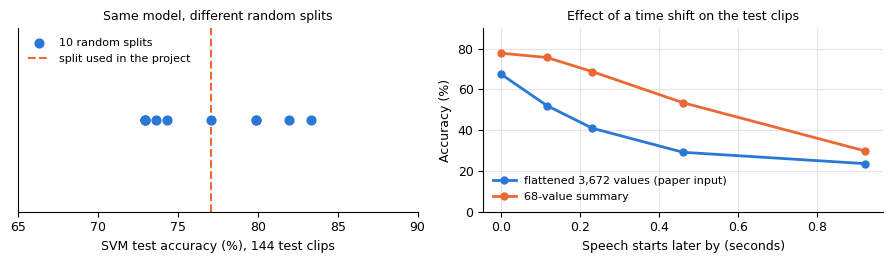

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.7))
ax = axes[0]
ax.scatter(100 * split_acc, np.zeros(10), s=40, color=BLUE, zorder=3, label="10 random splits")
ax.axvline(100 * reproduce.loc[0, "saved accuracy"], color=ORANGE, lw=1.5, ls="--", label="split used in the project")
ax.set_yticks([])
ax.set_xlabel("SVM test accuracy (%), 144 test clips")
ax.set_xlim(65, 90)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Same model, different random splits", fontsize=9)
ax = axes[1]
for (name, values), color in zip(position.items(), [BLUE, ORANGE]):
    ax.plot([s * 0.023 for s in shifts], 100 * values, marker="o", ms=5, lw=2, color=color, label=name)
ax.set_xlabel("Speech starts later by (seconds)")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 90)
ax.grid(color="#e6e5e0")
ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.set_title("Effect of a time shift on the test clips", fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "figures" / "fig3_split_and_shift.png", dpi=200)
plt.show()

## 6. Summary of the theoretical insights

In [13]:
print(f"1. Reproducible: SVM predictions identical to the saved run on "
      f"{100 * reproduce.loc[0, 'same predictions']:.1f}% (random split) and "
      f"{100 * reproduce.loc[2, 'same predictions']:.1f}% (unseen speakers) of clips.")
print(f"2. The features identify the speaker ({100 * speaker_id:.1f}%) better than the emotion ({100 * emotion_id:.1f}%).")
print(f"3. Speaker normalisation: unseen speakers {100 * normalisation.iloc[0, 0]:.1f}% -> "
      f"{100 * normalisation.iloc[1, 0]:.1f}%, gender gap {100 * normalisation.iloc[0, 3]:.1f} -> "
      f"{100 * normalisation.iloc[1, 3]:.1f} points, TESS {100 * normalisation.iloc[0, 4]:.1f}% -> "
      f"{100 * normalisation.iloc[1, 4]:.1f}%.")
print(f"4. Random split alone moves SVM accuracy between {100 * split_acc.min():.1f}% and {100 * split_acc.max():.1f}%.")
print(f"5. A 0.23 s delay (10 frames) changes accuracy by {100 * (position.loc[10].iloc[0] - position.loc[0].iloc[0]):+.1f} "
      f"points (flattened) vs {100 * (position.loc[10].iloc[1] - position.loc[0].iloc[1]):+.1f} (summary).")

1. Reproducible: SVM predictions identical to the saved run on 100.0% (random split) and 98.7% (unseen speakers) of clips.
2. The features identify the speaker (95.0%) better than the emotion (74.4%).
3. Speaker normalisation: unseen speakers 49.3% -> 59.2%, gender gap 7.5 -> 11.0 points, TESS 24.2% -> 34.8%.
4. Random split alone moves SVM accuracy between 72.9% and 83.3%.
5. A 0.23 s delay (10 frames) changes accuracy by -26.4 points (flattened) vs -9.0 (summary).
